<a href="https://colab.research.google.com/github/ZukhrufianAbdullah/PCVK_Ganjil_2026/blob/main/Week-10/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week10 – Object Detection (Modul 10)
Jalankan sel dari atas ke bawah. **Ubah `BASE`** di sel setup sesuai lokasi folder gambar di Google Drive Anda.
Fungsi `find()` mencari file secara rekursif di dalam `BASE`, jadi struktur subfolder bebas.

In [1]:
import os, glob
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# ====== UBAH SESUAI FOLDER DRIVE ANDA ======
BASE = '/content/drive/MyDrive/PCVK/Gambar'

def find(*names):
    # cari file (boleh beberapa kandidat nama) secara rekursif di BASE
    for n in names:
        hits = glob.glob(os.path.join(BASE, '**', n), recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError(f'Tidak ditemukan: {names} di {BASE}')

def show(img, title='', size=(8, 6), cmap=None):
    plt.figure(figsize=size)
    if img.ndim == 2:
        plt.imshow(img, cmap=cmap or 'gray')
    else:
        plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(title); plt.show()

def load_cascade(name):
    # cascade bawaan OpenCV (cv.data.haarcascades); fallback ke folder BASE
    p = os.path.join(cv.data.haarcascades, name)
    if not os.path.exists(p):
        p = find(name)
    c = cv.CascadeClassifier(p)
    assert not c.empty(), f'Gagal load {p}'
    return c

print('OpenCV', cv.__version__)

OpenCV 4.14.0


# D1. Praktikum Deteksi Obyek Dasar
Metode: 1. Template Matching 2. Edge Detection 3. Corner Detection 4. Grid Detection 5. Contour Detection

## 2. Template Matching (6 metode OpenCV)

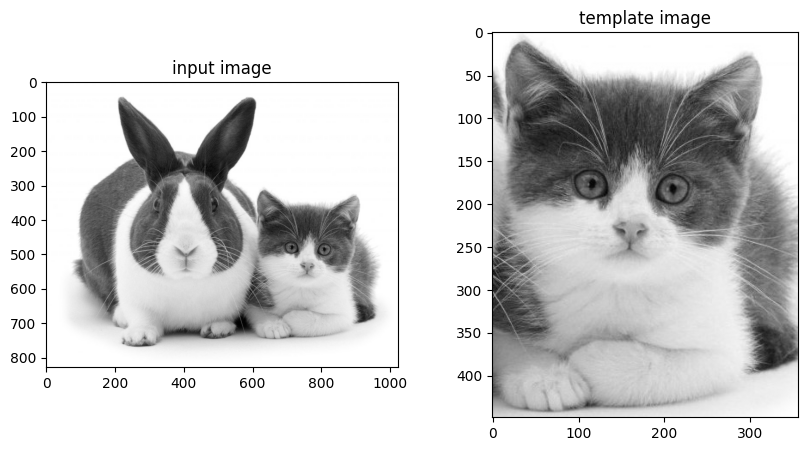

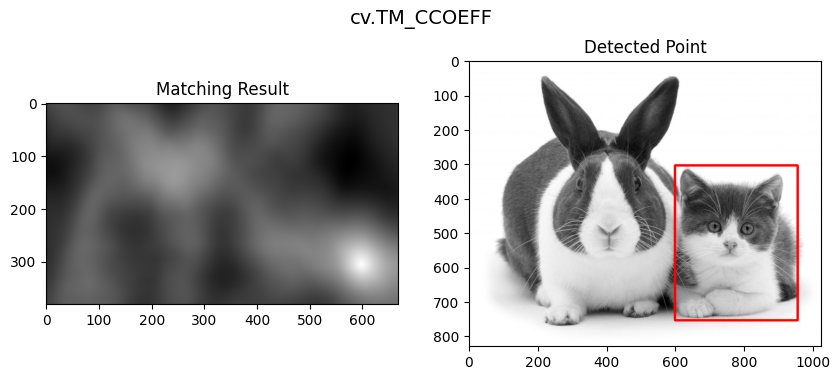

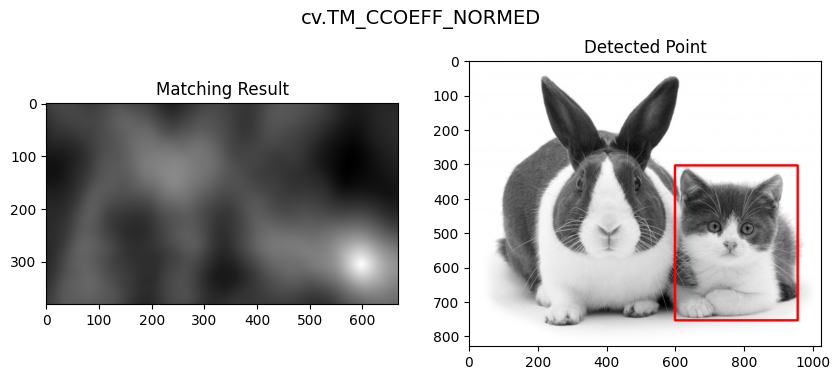

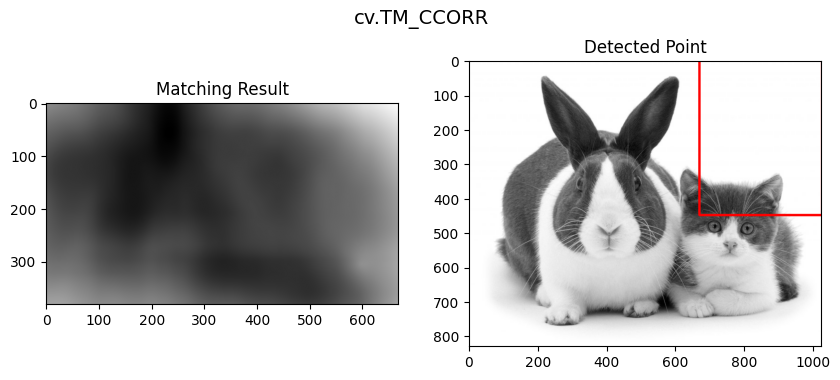

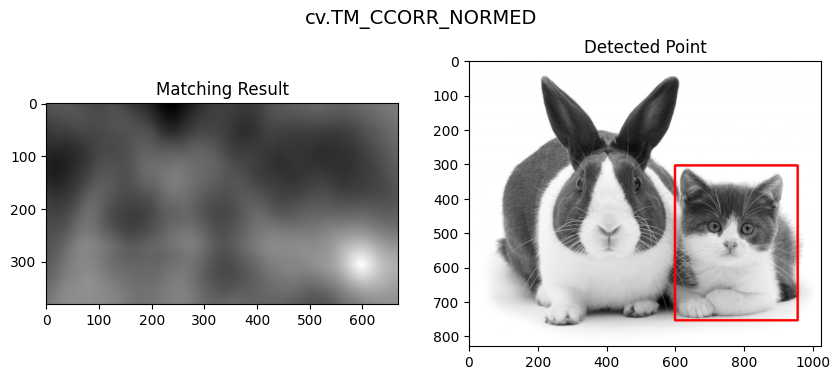

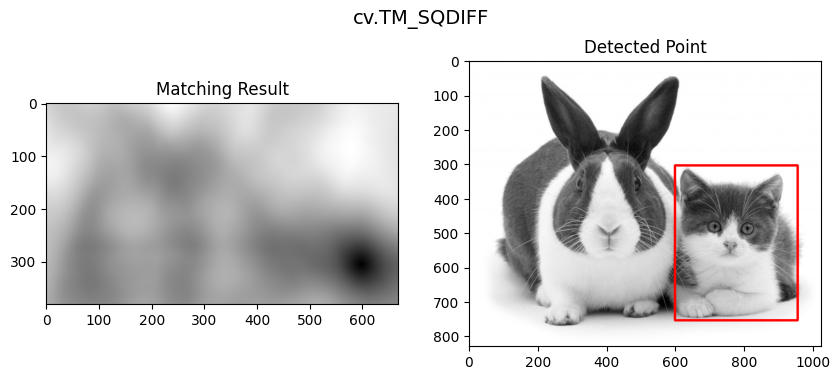

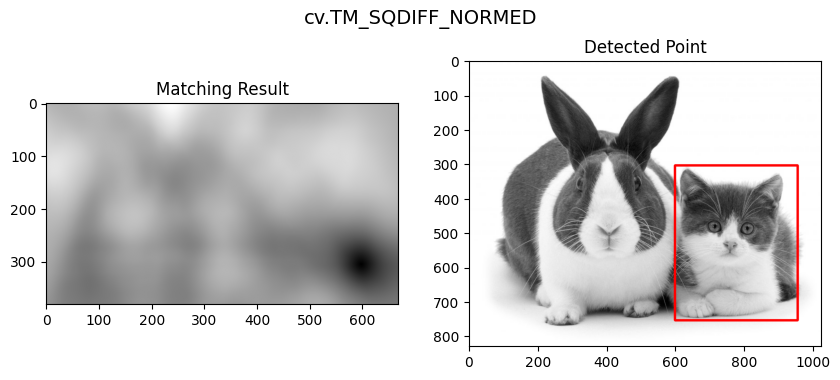

In [3]:
img = cv.imread(find('cats_and_bunnies.jpg'), 0)
template = cv.imread(find('cat2_template.jpg', 'cat2_templatejpg.jpg', 'cat2_template.jpg.jpg'), 0)
h, w = template.shape

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img, cmap='gray'); ax[0].set_title('input image')
ax[1].imshow(template, cmap='gray'); ax[1].set_title('template image')
plt.show()

methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
           'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

for m in methods:
    method = getattr(cv, m.split('.')[1])
    res = cv.matchTemplate(img, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)
    # SQDIFF: nilai terkecil = paling cocok; lainnya: nilai terbesar
    top_left = min_loc if method in (cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED) else max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)
    out = cv.cvtColor(img, cv.COLOR_GRAY2RGB)
    cv.rectangle(out, top_left, bottom_right, (255, 0, 0), 5)

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(res, cmap='gray'); ax[0].set_title('Matching Result')
    ax[1].imshow(out); ax[1].set_title('Detected Point')
    fig.suptitle(m, fontsize=14)
    plt.show()

## 3. Template Matching tanpa OpenCV (multiple object)
Memakai *Normalized Cross-Correlation* (zero-mean) yang dihitung dengan NumPy/SciPy (FFT + integral image),
lalu diambil semua puncak di atas threshold dengan *non-maximum suppression*.

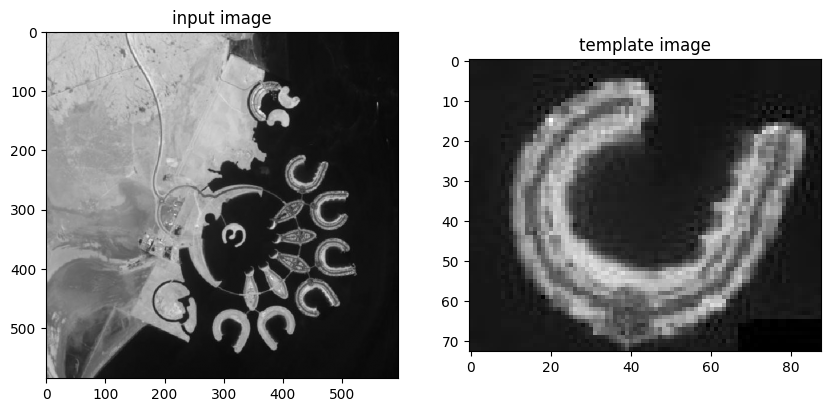

jumlah objek terdeteksi: 2


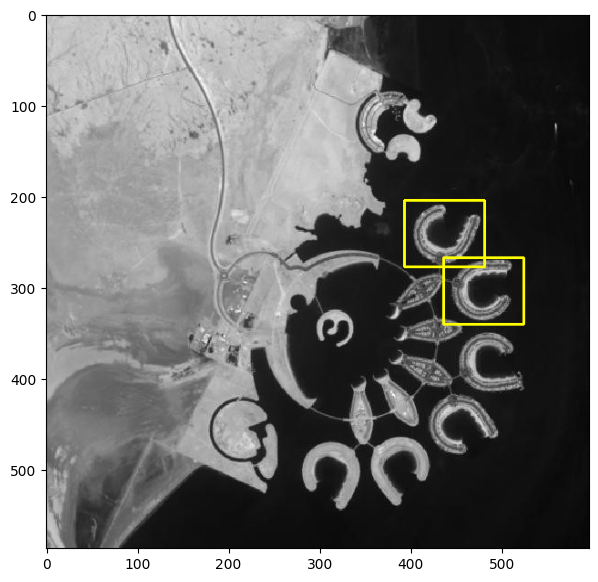

In [7]:
from scipy.signal import fftconvolve

def ncc_map(I, T):
    I = I.astype(np.float64); T = T.astype(np.float64)
    th, tw = T.shape; N = th * tw
    T0 = T - T.mean()
    num = fftconvolve(I, T0[::-1, ::-1], mode='valid')       # korelasi
    ii  = np.pad(I.cumsum(0).cumsum(1),      ((1, 0), (1, 0)))
    ii2 = np.pad((I ** 2).cumsum(0).cumsum(1), ((1, 0), (1, 0)))
    box = lambda a: a[th:, tw:] - a[:-th, tw:] - a[th:, :-tw] + a[:-th, :-tw]
    s1, s2 = box(ii), box(ii2)
    var = np.maximum(s2 - s1 ** 2 / N, 1e-9)
    return num / (np.sqrt(var) * np.sqrt((T0 ** 2).sum()) + 1e-9)

def find_peaks(R, th, tw, thr, max_n=50):
    R = R.copy(); found = []
    while len(found) < max_n:
        y, x = np.unravel_index(np.argmax(R), R.shape)
        if R[y, x] < thr:
            break
        found.append((x, y, R[y, x]))
        R[max(0, y - th // 2): y + th // 2 + 1, max(0, x - tw // 2): x + tw // 2 + 1] = -1
    return found

src_color = cv.imread(find('bahrain.jpg'))
src_gray  = cv.cvtColor(src_color, cv.COLOR_BGR2GRAY)
tmpl_gray = cv.imread(find('bahrain-template.jpg', 'bahrain_template.jpg'), 0)
th, tw = tmpl_gray.shape

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(src_gray, cmap='gray'); ax[0].set_title('input image')
ax[1].imshow(tmpl_gray, cmap='gray'); ax[1].set_title('template image')
plt.show()

THRESHOLD = 0.55          # naikkan jika terlalu banyak kotak, turunkan jika ada yang terlewat
R = ncc_map(src_gray, tmpl_gray)
peaks = find_peaks(R, th, tw, THRESHOLD)
print('jumlah objek terdeteksi:', len(peaks))

out = cv.cvtColor(src_gray, cv.COLOR_GRAY2RGB)
for x, y, s in peaks:
    cv.rectangle(out, (x, y), (x + tw, y + th), (255, 255, 0), 2)
plt.figure(figsize=(7, 7)); plt.imshow(out); plt.show()

## 4. Edge Detection (Sobel, Canny, Laplacian) – car-park.jpg

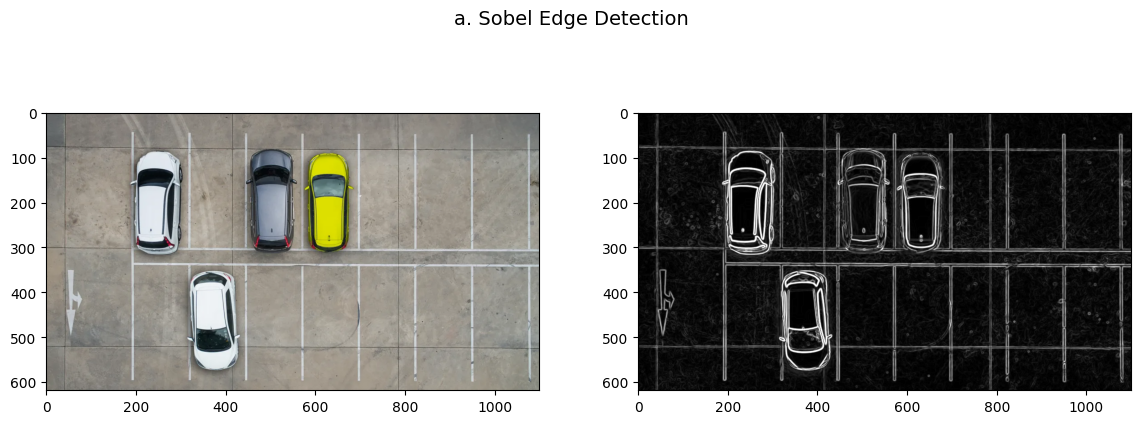

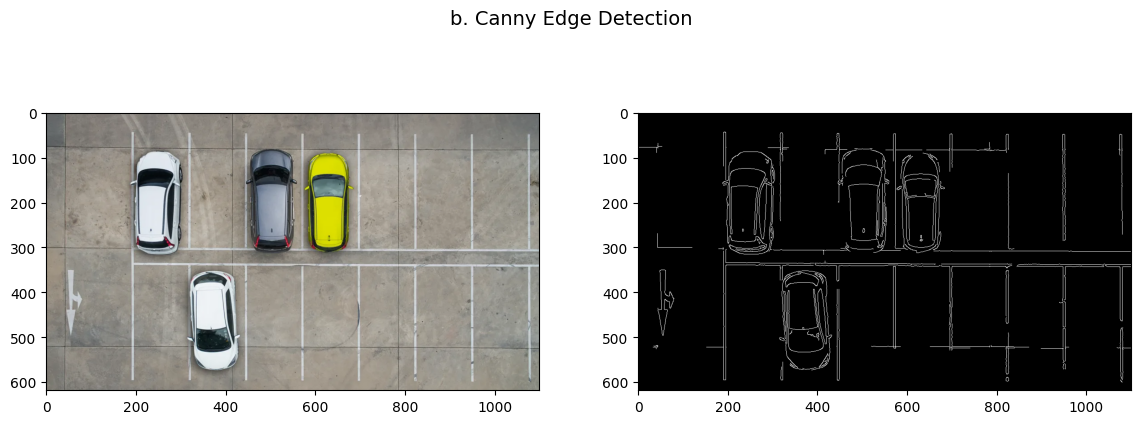

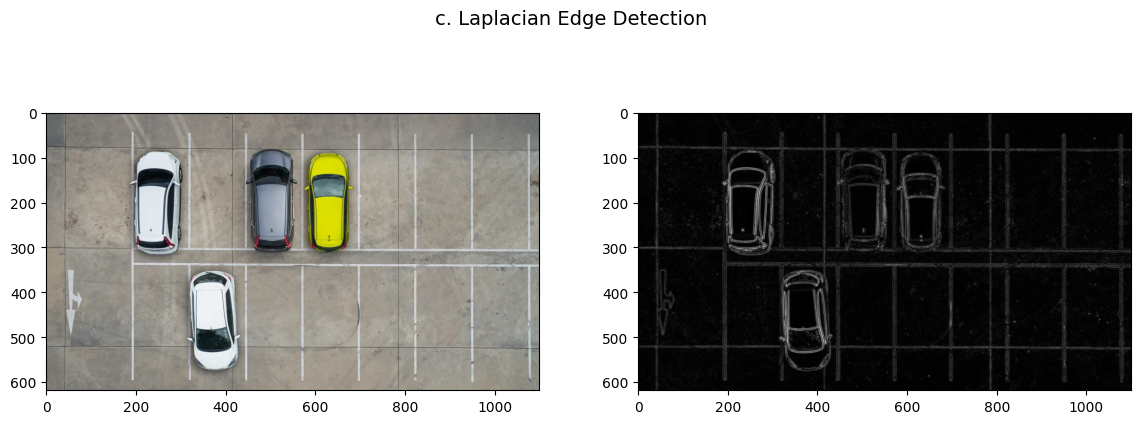

In [8]:
car = cv.imread(find('car-park.jpg'))
gray = cv.cvtColor(car, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(gray, (5, 5), 0)

def pair(orig, res, title):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].imshow(cv.cvtColor(orig, cv.COLOR_BGR2RGB)); ax[1].imshow(res, cmap='gray')
    fig.suptitle(title, fontsize=14); plt.show()

# a. Sobel
sx = cv.Sobel(blur, cv.CV_64F, 1, 0, ksize=3)
sy = cv.Sobel(blur, cv.CV_64F, 0, 1, ksize=3)
sobel = cv.convertScaleAbs(np.sqrt(sx ** 2 + sy ** 2))
pair(car, sobel, 'a. Sobel Edge Detection')

# b. Canny
canny = cv.Canny(blur, 100, 200)
pair(car, canny, 'b. Canny Edge Detection')

# c. Laplacian (dihaluskan Gaussian dulu)
lap = cv.convertScaleAbs(cv.Laplacian(blur, cv.CV_64F, ksize=3))
pair(car, lap, 'c. Laplacian Edge Detection')

## 5. Corner Detection (Harris & Shi-Tomasi) – chess-board.jpg

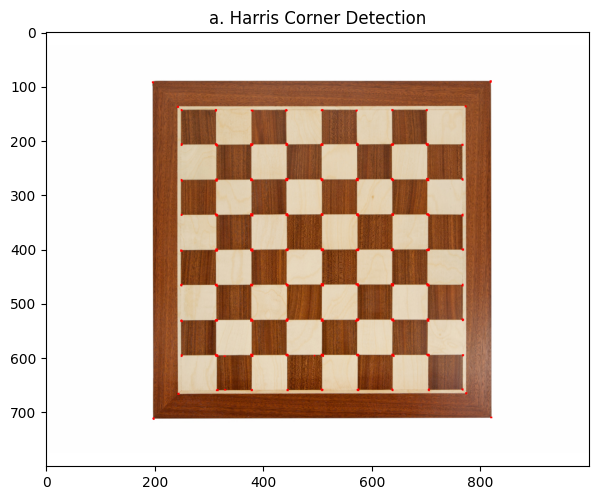

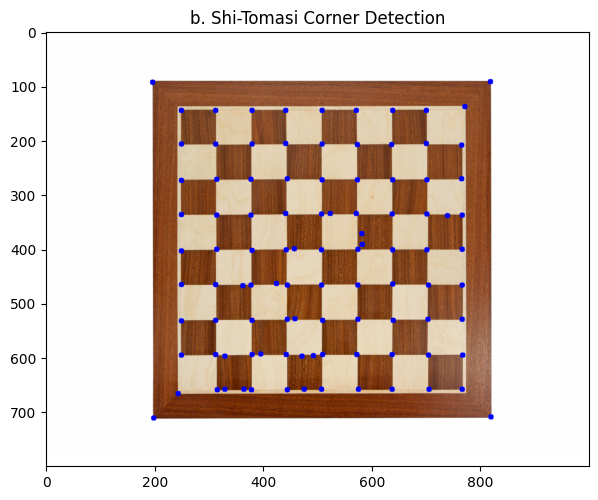

In [9]:
chess = cv.imread(find('chess-board.jpg', 'chessboard.jpg'))
gray = cv.cvtColor(chess, cv.COLOR_BGR2GRAY)

# a. Harris
harris = cv.cornerHarris(np.float32(gray), blockSize=2, ksize=3, k=0.04)
harris = cv.dilate(harris, None)
out_h = chess.copy()
out_h[harris > 0.01 * harris.max()] = [0, 0, 255]
show(out_h, 'a. Harris Corner Detection', size=(7, 7))

# b. Shi-Tomasi
corners = cv.goodFeaturesToTrack(gray, maxCorners=100, qualityLevel=0.01, minDistance=10)
out_s = chess.copy()
for c in np.int32(corners).reshape(-1, 2):
    cv.circle(out_s, tuple(c), 5, (255, 0, 0), -1)      # biru (BGR)
show(out_s, 'b. Shi-Tomasi Corner Detection', size=(7, 7))

## 6. Grid Detection – Hough Transform (sudoku.jpg)
Tahapan: Canny → dilasi → erosi → `cv.HoughLines` → gabungkan garis yang mirip.

garis mentah: 29 | setelah digabung: 13


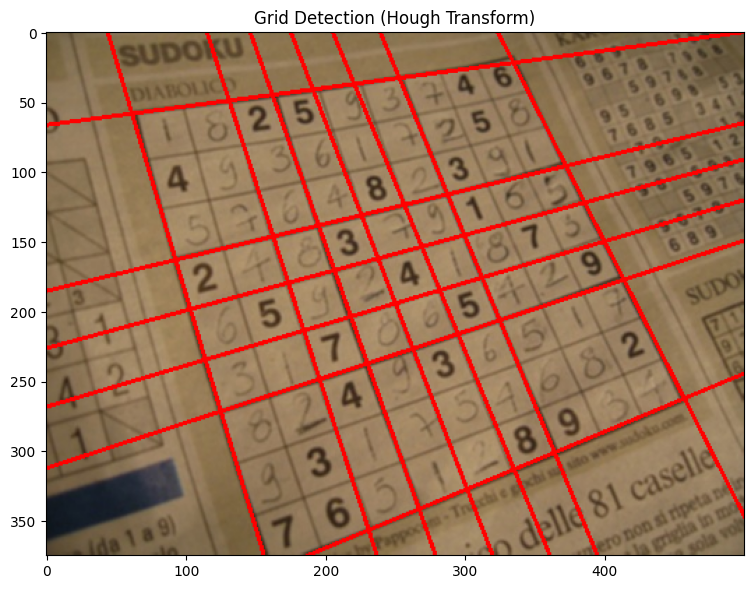

In [35]:
sudoku = cv.imread(find('sudoku.jpg'))
gray = cv.cvtColor(sudoku, cv.COLOR_BGR2GRAY)

edges = cv.Canny(gray, 120, 250, apertureSize=3)                 # 1. Canny
kernel = np.ones((3, 3), np.uint8)
edges = cv.dilate(edges, kernel, iterations=1)                  # 2. dilasi
edges = cv.erode(edges, kernel, iterations=1)                   # 3. erosi
lines = cv.HoughLines(edges, 1, np.pi / 120, 180)               # 4. HoughLines (ubah threshold bila perlu)

def merge_lines(lines, rho_t=20, theta_t=np.pi / 18):
    # 5. gabungkan garis yang mirip (rho & theta berdekatan)
    merged = []
    for l in lines:
        rho, theta = l[0]
        if rho < 0:                       # normalisasi agar rho >= 0
            rho, theta = -rho, theta - np.pi
        for m in merged:
            if abs(m[0] - rho) < rho_t and abs(m[1] - theta) < theta_t:
                break
        else:
            merged.append((rho, theta))
    return merged

out = sudoku.copy()
if lines is None:
    print('Tidak ada garis; turunkan threshold HoughLines.')
else:
    merged = merge_lines(lines)
    print('garis mentah:', len(lines), '| setelah digabung:', len(merged))
    for rho, theta in merged:
        a, b = np.cos(theta), np.sin(theta)
        x0, y0 = a * rho, b * rho
        p1 = (int(x0 + 2000 * (-b)), int(y0 + 2000 * a))
        p2 = (int(x0 - 2000 * (-b)), int(y0 - 2000 * a))
        cv.line(out, p1, p2, (0, 0, 255), 2)
show(out, 'Grid Detection (Hough Transform)', size=(9, 7))

## 7. Contour Detection – laptop.jpg

jumlah kontur: 20


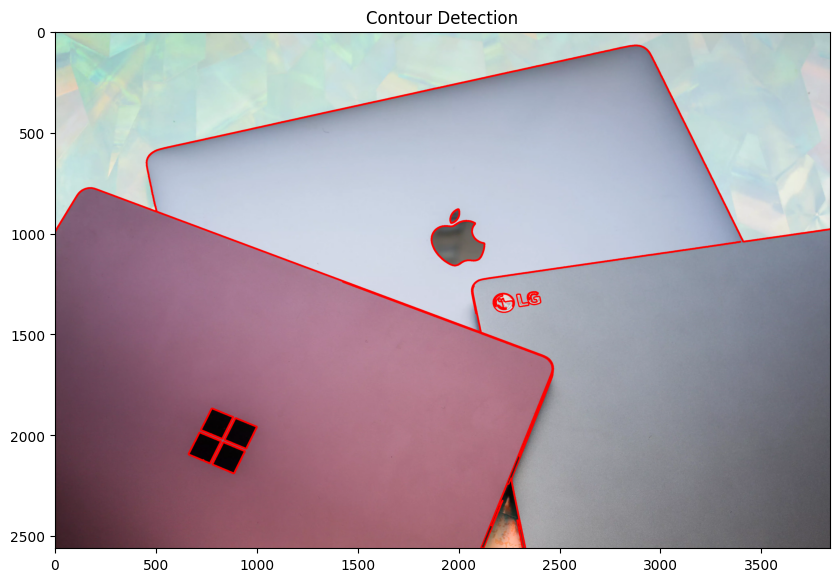

In [36]:
laptop = cv.imread(find('laptop.jpg'))
gray = cv.cvtColor(laptop, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(gray, (7, 7), 0)
edges = cv.Canny(blur, 30, 100)                                  # citra biner
edges = cv.dilate(edges, np.ones((3, 3), np.uint8), iterations=1)

contours, hierarchy = cv.findContours(edges, cv.RETR_LIST, cv.CHAIN_APPROX_SIMPLE)
contours = [c for c in contours if cv.contourArea(c) > 500]      # buang kontur noise kecil
print('jumlah kontur:', len(contours))

out = laptop.copy()
cv.drawContours(out, contours, -1, (0, 0, 255), 5)
show(out, 'Contour Detection', size=(10, 8))

# D2. Praktikum Feature Matching dan Face Detection
### (Opsional – demo teori) ORB vs SIFT pada `reeses_puffs.png` dan `many_cereals.jpg`

ORB matches: 139


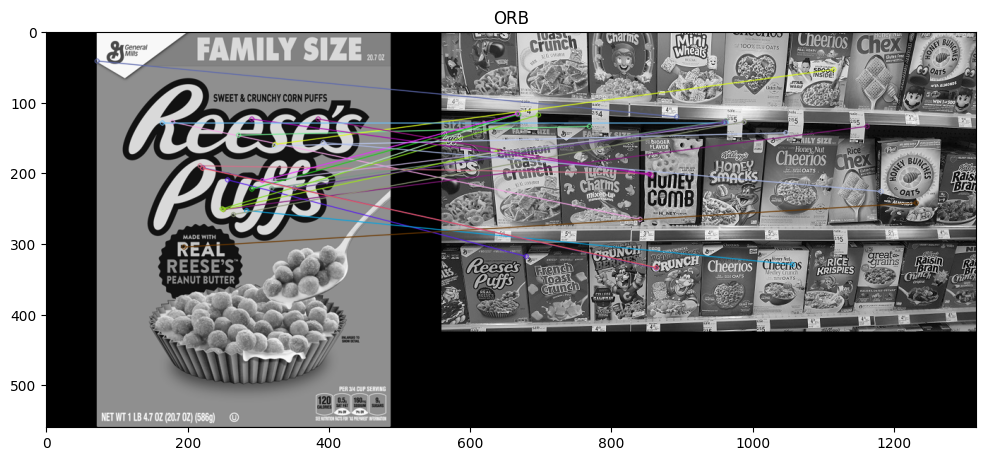

SIFT good matches: 79 dari 1501


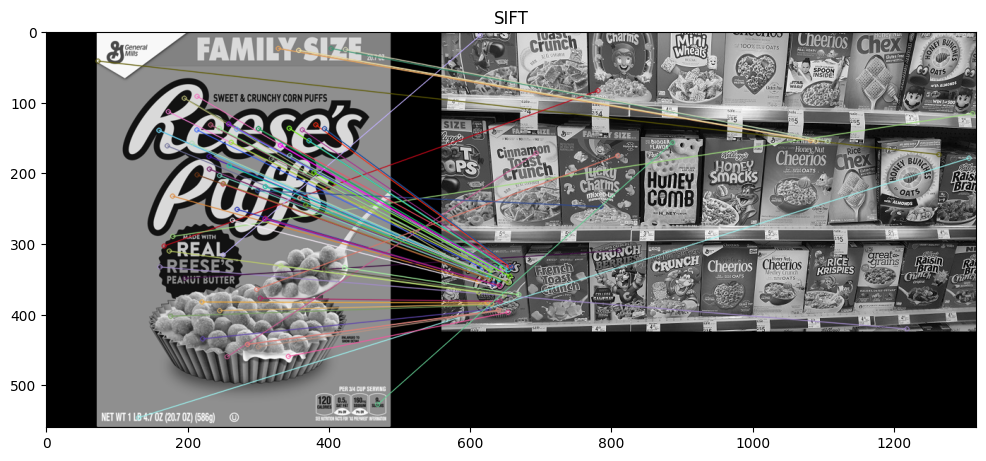

In [38]:
reeses  = cv.imread(find('reeses_puffs.png'), 0)
cereals = cv.imread(find('many_cereals.jpg'), 0)

# ORB + Brute-Force (Hamming)
orb = cv.ORB_create()
kp1, des1 = orb.detectAndCompute(reeses, None)
kp2, des2 = orb.detectAndCompute(cereals, None)
bf = cv.BFMatcher(cv.NORM_HAMMING, crossCheck=True)
matches = sorted(bf.match(des1, des2), key=lambda x: x.distance)
print('ORB matches:', len(matches))
show(cv.drawMatches(reeses, kp1, cereals, kp2, matches[:25], None, flags=2), 'ORB', size=(12, 10))

# SIFT + Brute-Force kNN + ratio test
sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(reeses, None)
kp2, des2 = sift.detectAndCompute(cereals, None)
knn = cv.BFMatcher().knnMatch(des1, des2, k=2)
good = [[m1] for m1, m2 in knn if m1.distance < 0.75 * m2.distance]
print('SIFT good matches:', len(good), 'dari', len(knn))
show(cv.drawMatchesKnn(reeses, kp1, cereals, kp2, good, None, flags=2), 'SIFT', size=(12, 10))

## 8. Face Detection pada semua gambar di folder `facedet`

Folder facedet: /content/drive/MyDrive/PCVK/Gambar


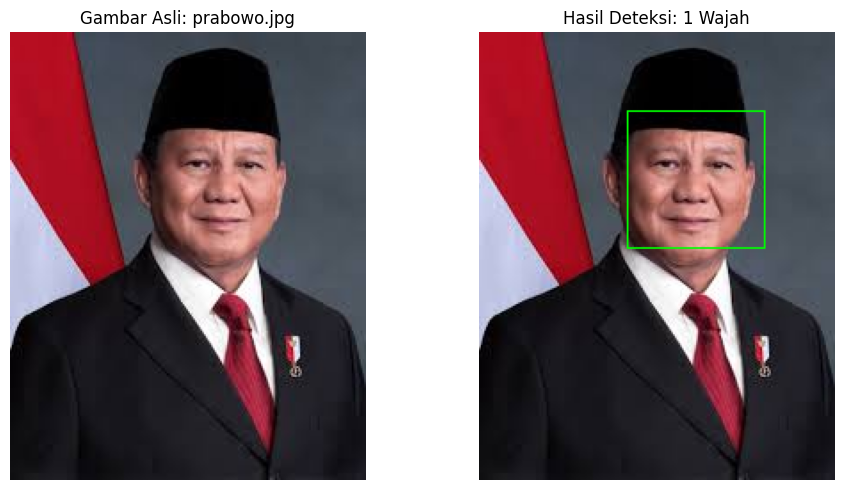

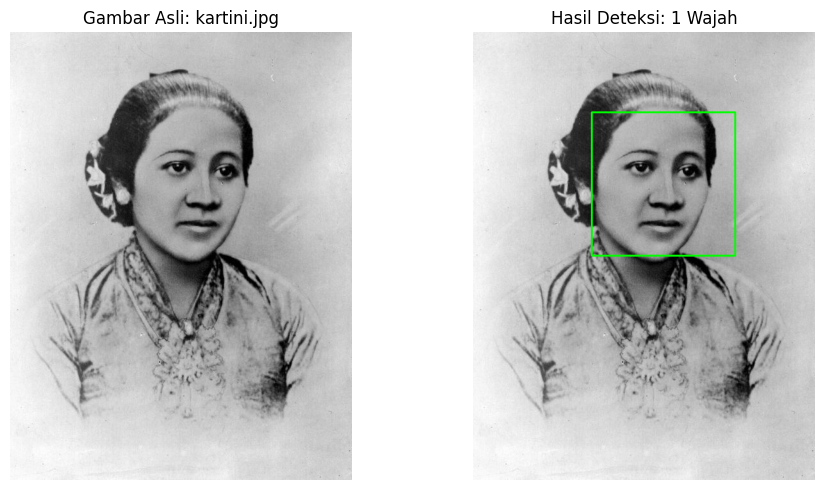

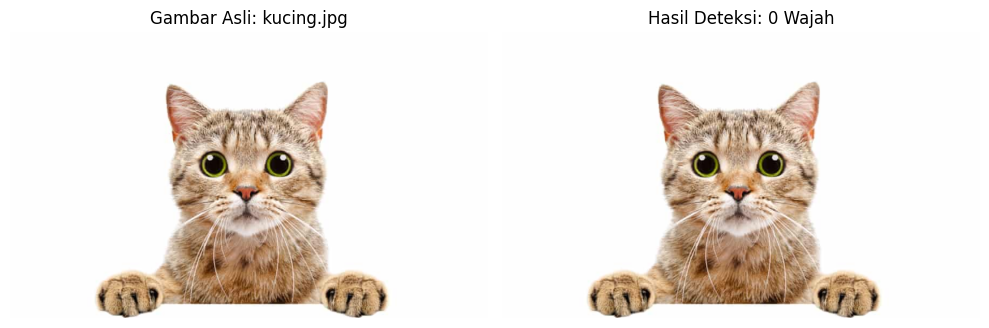

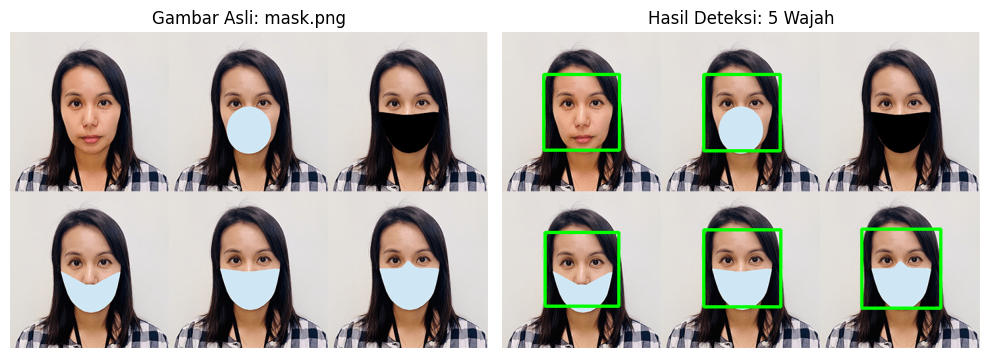

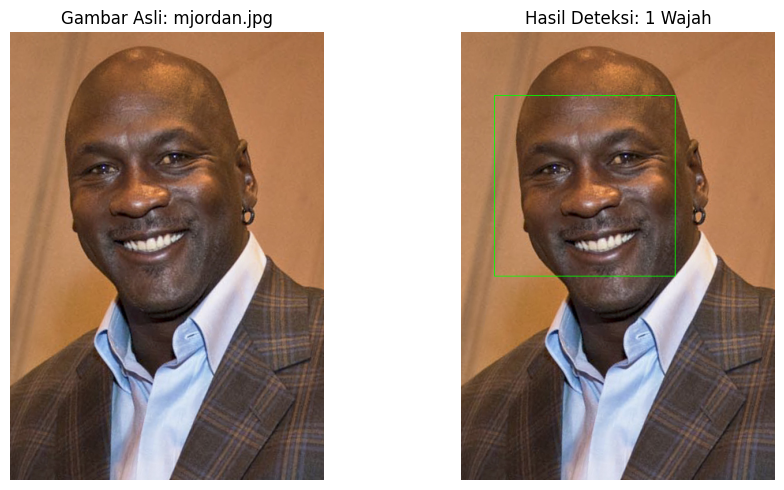

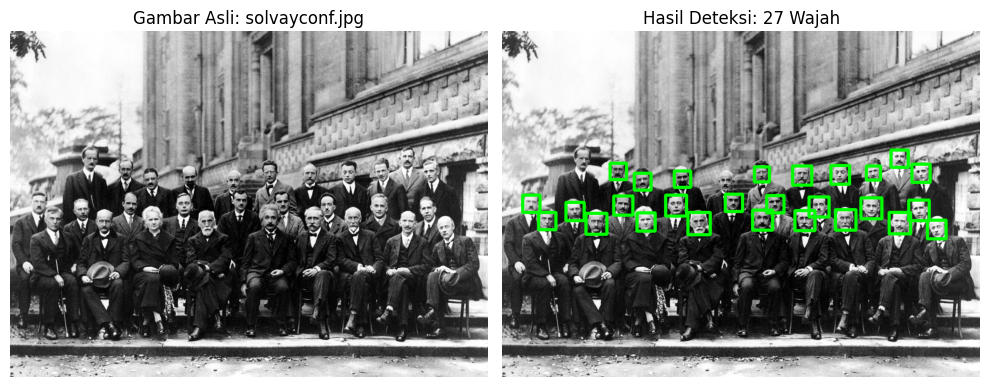

In [47]:
face_cascade = load_cascade('haarcascade_frontalface_alt.xml')

FACEDET = os.path.dirname(find('prabowo.jpg'))
print('Folder facedet:', FACEDET)

def pick(keyword):
    for f in sorted(os.listdir(FACEDET)):
        if keyword.lower() == f.lower() and f.lower().endswith(('.jpg', '.jpeg', '.png')):
            return os.path.join(FACEDET, f)
    raise FileNotFoundError(f"File '{keyword}' tidak ditemukan di {FACEDET}")

def detect_faces(gray, scale=1.1, neigh=5, cascade=face_cascade):
    return cascade.detectMultiScale(
        gray,
        scaleFactor=scale,
        minNeighbors=neigh
    )

# Daftar gambar yang akan diproses saja
image_list = [
    'prabowo.jpg',
    'kartini.jpg',
    'kucing.jpg',
    'mask.png',
    'mjordan.jpg',
    'solvayconf.jpg'
]

# Proses deteksi wajah pada setiap gambar
for filename in image_list:

    path = pick(filename)

    im = cv.imread(path)

    if im is None:
        print(f'Gagal membaca gambar: {filename}')
        continue

    g = cv.cvtColor(im, cv.COLOR_BGR2GRAY)
    res = im.copy()

    # Deteksi wajah
    faces = detect_faces(g)

    for (x, y, w, h) in faces:
        cv.rectangle(
            res,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            max(1, im.shape[1] // 200)
        )

    # Menampilkan gambar asli dan hasil deteksi
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))

    ax[0].imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
    ax[0].set_title(f'Gambar Asli: {filename}')

    ax[1].imshow(cv.cvtColor(res, cv.COLOR_BGR2RGB))
    ax[1].set_title(f'Hasil Deteksi: {len(faces)} Wajah')

    ax[0].axis('off')
    ax[1].axis('off')

    plt.tight_layout()
    plt.show()

## 9. Deteksi wajah kucing (cascade `haarcascade_frontalcatface_extended.xml`)

wajah kucing: 1


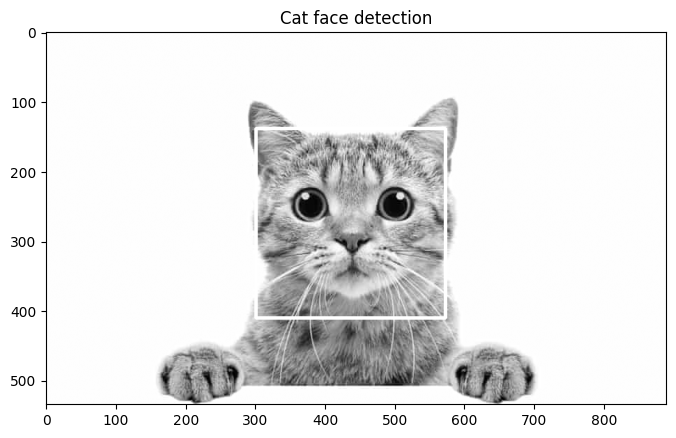

In [49]:
cat_cascade = load_cascade('haarcascade_frontalcatface_extended.xml')
cat = cv.imread(pick('kucing.jpg'), 0)
rects = cat_cascade.detectMultiScale(cat, scaleFactor=1.05, minNeighbors=3, minSize=(75, 75))
print('wajah kucing:', len(rects))
out = cat.copy()
for (x, y, w, h) in rects:
    cv.rectangle(out, (x, y), (x + w, y + h), 255, 3)
show(out, 'Cat face detection', size=(8, 6))

## 10. Eyes detection pada wajah Pak Prabowo

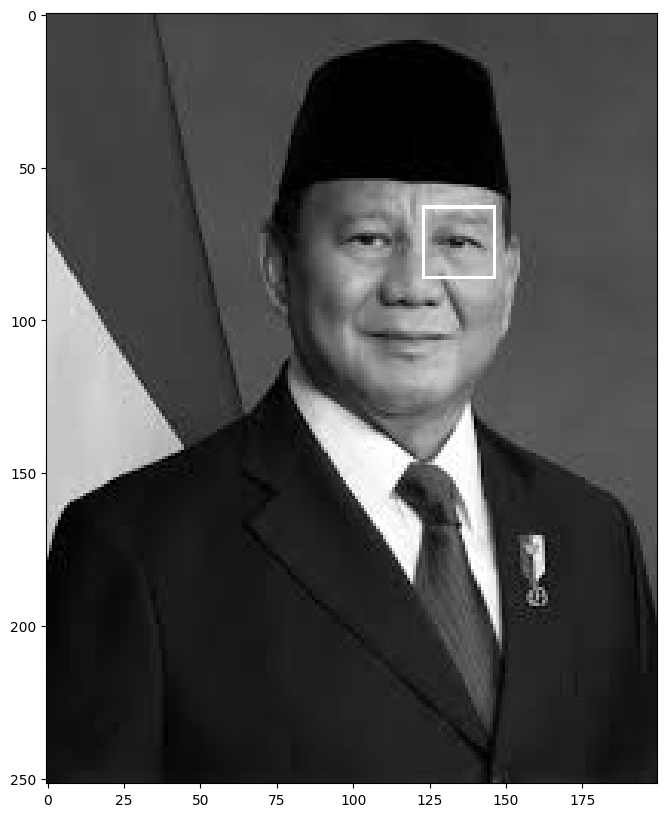

In [50]:
eye_cascade = load_cascade('haarcascade_eye.xml')
pic = cv.imread(find('prabowo.jpg'), 0)
out = pic.copy()
for (fx, fy, fw, fh) in detect_faces(pic):
    roi = pic[fy:fy + fh, fx:fx + fw]
    for (ex, ey, ew, eh) in eye_cascade.detectMultiScale(roi, 1.1, 5):
        cv.rectangle(out, (fx + ex, fy + ey), (fx + ex + ew, fy + ey + eh), 255, 1)
plt.figure(figsize=(8, 10)); plt.imshow(out, cmap='gray'); plt.show()

## 11. Deteksi senyuman – gambar `people`

senyuman terdeteksi: 3


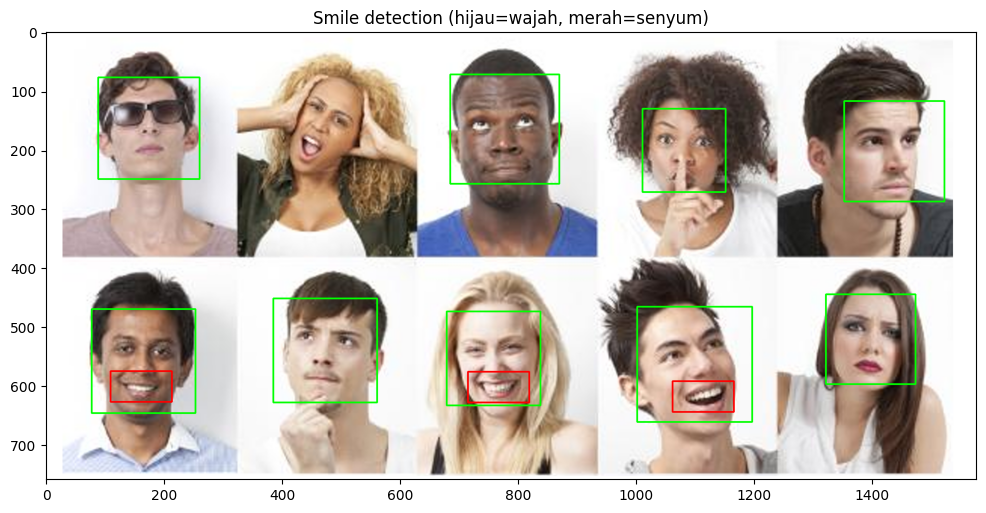

In [51]:
smile_cascade = load_cascade('haarcascade_smile.xml')
people = cv.imread(pick('people.jpg'))
g = cv.cvtColor(people, cv.COLOR_BGR2GRAY)
out = people.copy()
n = 0
for (x, y, w, h) in detect_faces(g):
    cv.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 2)
    roi = g[y + h // 2: y + h, x: x + w]                      # senyum dicari di separuh bawah wajah
    for (sx, sy, sw, sh) in smile_cascade.detectMultiScale(roi, scaleFactor=1.7, minNeighbors=20):
        cv.rectangle(out, (x + sx, y + h // 2 + sy), (x + sx + sw, y + h // 2 + sy + sh), (0, 0, 255), 2)
        n += 1
print('senyuman terdeteksi:', n)
show(out, 'Smile detection (hijau=wajah, merah=senyum)', size=(12, 7))

## 12. Face Tracking dengan kamera (Google Colab)
Colab tidak bisa membaca webcam langsung, jadi dipakai JavaScript. Jalankan sel, izinkan kamera, klik **Capture**.
Panggil `track(n)` untuk mengambil n frame berturut-turut. Untuk video *live* penuh, ikuti tutorial YouTube pada modul.

In [ ]:
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename='photo.jpg', quality=0.9):
    js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => capture.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    with open(filename, 'wb') as f:
        f.write(b64decode(data.split(',')[1]))
    return filename

def track(n=3):
    for i in range(n):
        fn = take_photo(f'frame{i}.jpg')
        frame = cv.imread(fn)
        g = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
        for (x, y, w, h) in detect_faces(g):
            cv.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 3)
        show(frame, f'Frame {i + 1}')

track(3)

## 13. Blurring wajah yang terdeteksi (`cv.medianBlur`)

In [ ]:
jordan = cv.imread(pick('jordan') if any('jordan' in f.lower() for f in os.listdir(FACEDET)) else pick('michael'))
out = jordan.copy()
for (x, y, w, h) in detect_faces(cv.cvtColor(jordan, cv.COLOR_BGR2GRAY)):
    out[y:y + h, x:x + w] = cv.medianBlur(out[y:y + h, x:x + w], 51)   # ukuran kernel harus ganjil
show(out, 'Face blurring', size=(6, 8))

## 14. Mengolah gambar KTM
Siapkan `ktm.jpg` (foto KTM Anda) dan `ktm_scene.jpg` (KTM bersama barang lain), simpan di folder `BASE`.

In [ ]:
# a. Tampilkan KTM
ktm = cv.imread(find('ktm.jpg'))
show(ktm, 'a. KTM', size=(9, 6))

# b. Crop foto KTM: latar foto berwarna merah -> cari area merah terbesar
hsv = cv.cvtColor(ktm, cv.COLOR_BGR2HSV)
mask = cv.inRange(hsv, (0, 120, 70), (10, 255, 255)) | cv.inRange(hsv, (170, 120, 70), (180, 255, 255))
mask = cv.morphologyEx(mask, cv.MORPH_CLOSE, np.ones((9, 9), np.uint8))
cnts, _ = cv.findContours(mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
if cnts:
    x, y, w, h = cv.boundingRect(max(cnts, key=cv.contourArea))
else:                                    # cadangan: perluas kotak wajah hasil Haar Cascade
    fx, fy, fw, fh = detect_faces(cv.cvtColor(ktm, cv.COLOR_BGR2GRAY))[0]
    x, y, w, h = int(fx - .6 * fw), int(fy - .6 * fh), int(2.2 * fw), int(2.4 * fh)
    x, y = max(x, 0), max(y, 0)
foto = ktm[y:y + h, x:x + w]
plt.figure(figsize=(4, 4)); plt.imshow(cv.cvtColor(foto, cv.COLOR_BGR2RGB)); plt.title('FOTO KTM'); plt.axis('off'); plt.show()

In [ ]:
# c. Deteksi KTM pada gambar berisi barang lain – Feature Matching (SIFT + ratio test + homography)
tmpl  = cv.imread(find('ktm.jpg'))
scene = cv.imread(find('ktm_scene.jpg', 'ktm_barang.jpg'))
sift = cv.SIFT_create()
kp1, d1 = sift.detectAndCompute(cv.cvtColor(tmpl, cv.COLOR_BGR2GRAY), None)
kp2, d2 = sift.detectAndCompute(cv.cvtColor(scene, cv.COLOR_BGR2GRAY), None)
knn = cv.BFMatcher().knnMatch(d1, d2, k=2)
good = [m for m, n in knn if m.distance < 0.75 * n.distance]
print('good matches:', len(good))

if len(good) >= 10:
    src = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    M, inl = cv.findHomography(src, dst, cv.RANSAC, 5.0)
    h, w = tmpl.shape[:2]
    pts = np.float32([[0, 0], [0, h - 1], [w - 1, h - 1], [w - 1, 0]]).reshape(-1, 1, 2)
    box = cv.perspectiveTransform(pts, M)
    result = scene.copy()
    cv.polylines(result, [np.int32(box)], True, (0, 255, 0), 6)
    show(result, 'KTM terdeteksi', size=(10, 7))
    vis = cv.drawMatches(tmpl, kp1, scene, kp2, good, None, matchesMask=inl.ravel().tolist(), flags=2)
    show(vis, 'Feature matches (inlier)', size=(14, 7))
else:
    print('Fitur kurang. Gunakan foto KTM yang tajam / resolusi lebih besar.')

# D3. Tugas Pengayaan – Pengenalan Karakter KTM dengan CNN
Struktur dataset (di dalam `WORK`):
```
dataset/training/0 ... 9/ (banyak gambar per angka, juga A..Z bila perlu)
dataset/testing/<nama_ktm>/01.png 02.png 03.png ...   # urutan karakter, beri nomor 2 digit agar urutan sorted benar
```

In [ ]:
WORK = BASE + '/ktm_cnn'
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
print('Working dir:', os.getcwd(), '| isi:', os.listdir('.'))

In [ ]:
# --- Persiapan data training ---
import random, pickle
from tqdm import tqdm

DATADIR = "dataset/training"      # satu subfolder per karakter: 0..9, A..Z
width, height = 100, 100

dirs = sorted(os.listdir(DATADIR))
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for im in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv.imread(os.path.join(path, im), cv.IMREAD_GRAYSCALE)
            new_array = cv.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)
X, Y = [], []
for feature, label in training_data:
    X.append(feature); Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open("X.pickle", "wb"))
pickle.dump(Y, open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))
print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

In [ ]:
# --- Training CNN ---
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, ZeroPadding2D
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))
Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]

inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy', metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('anpr.keras')
print("akurasi training :", riwayat.history['accuracy'][-1])
print("akurasi validasi :", riwayat.history['val_accuracy'][-1])

In [ ]:
# --- Testing: baca karakter KTM ---
import tensorflow as tf

data_dir_testing = "dataset/testing"
model = tf.keras.models.load_model("anpr.keras")
dirs = pickle.load(open("kelas.pickle", "rb"))       # urutan kelas saat training

for car in sorted(os.listdir(data_dir_testing)):
    temp = ""
    folder = os.path.join(data_dir_testing, car)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv.imread(os.path.join(folder, char_img), cv.IMREAD_GRAYSCALE)
        new_array = cv.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]
    print("folder name: {} no: {}".format(car, temp))